In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from rm_noise import camb_spectra, so_lat_instrument, Geometry, reconstruction_noise, noise_dl


In [3]:
LMAX_CMB, LMAX_RM = 5000, 100
FSKY, SENSITIVITY = 0.6, "baseline"
USE_TB = True
RESIDUALS = [1., 0.5, 0.14, 0.]

In [4]:
instrument = so_lat_instrument(LMAX_CMB, FSKY, SENSITIVITY)
print("Bands GHz:", instrument[0])
prim, lensed = camb_spectra(LMAX_CMB)
geo = Geometry(LMAX_CMB, LMAX_RM)

Bands GHz: [ 27.  39.  93. 145. 225. 280.]


In [5]:
L = np.arange(1, LMAX_RM+1)
curves = {f: noise_dl(reconstruction_noise(geo, prim, lensed, instrument, f, USE_TB))[1:]
          for f in RESIDUALS}
for f, y in curves.items():
    print(f, 'D at L=1,10,30,100:', y[np.array([1,10,30,100])-1])

1.0 D at L=1,10,30,100: [9.92268829e+01 5.46069926e+03 4.63720127e+04 5.26604634e+05]
0.5 D at L=1,10,30,100: [9.75395374e+01 5.36784708e+03 4.55839767e+04 5.17745051e+05]
0.14 D at L=1,10,30,100: [9.61384373e+01 5.29074406e+03 4.49294437e+04 5.10366900e+05]
0.0 D at L=1,10,30,100: [9.55493052e+01 5.25832342e+03 4.46541901e+04 5.07260164e+05]


f_DL=1: largest L with 1 nG signal above noise = 6
f_DL=0.5: largest L with 1 nG signal above noise = 6
f_DL=0.14: largest L with 1 nG signal above noise = 6
f_DL=0: largest L with 1 nG signal above noise = 6


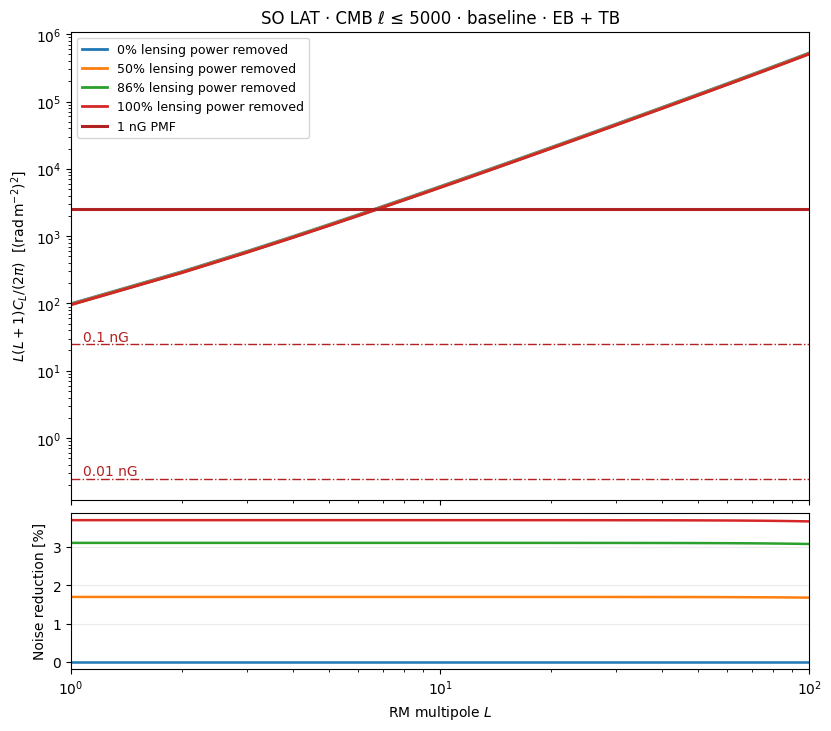

In [6]:
fig, (ax, ratio) = plt.subplots(2, 1, sharex=True, figsize=(8.2, 7.2),
                                height_ratios=[3, 1], layout="constrained")
undelensed = curves[1.] if 1. in curves else noise_dl(reconstruction_noise(geo, prim, lensed, instrument, 1., USE_TB))[1:]
for f, y in curves.items():
    ratio.semilogx(L, 100*(1-y/undelensed), lw=1.8)
    ax.loglog(L, y, lw=2, label=f"{100*(1-f):g}% lensing power removed")
field_ng = 1.0
signal = (50 * field_ng)**2
ax.axhline(signal, color="firebrick", lw=2.2, label="1 nG PMF")
for f, noise in curves.items():
    above = L[signal > noise]
    print(f"f_DL={f:g}: largest L with 1 nG signal above noise = {above.max() if above.size else 'none'}")
for field in [0.1,0.01]:
    ax.axhline((50*field)**2, color="firebrick", ls="-.", lw=1)
    ax.text(1.08,(50*field)**2*1.1, f"{field} nG", color="firebrick")
ax.set(xlim=(1,LMAX_RM),
       ylabel=r"$L(L+1) C_L/(2\pi)$  $[(\mathrm{rad}\,\mathrm{m}^{-2})^2]$",
       title=f"SO LAT · CMB ℓ ≤ {LMAX_CMB} · {SENSITIVITY} · {'EB + TB' if USE_TB else 'EB only'}")
ax.legend(fontsize=9)
ratio.set(xlabel="RM multipole $L$", ylabel="Noise reduction [%]")
ratio.grid(axis="y", alpha=0.25)
plt.show()